# Higgs Boson Machine Learning Challenge
**NTI | Machine Learning Project** — classify ATLAS collision events as signal (`s`) or background (`b`).

**Plan:** (1) understand the data, (2) EDA with a question behind every plot, (3) preprocessing and a leak-free validation design, (4) baselines, (5) `-999` and weight experiments, (6) model comparison, (7) accuracy vs ROC-AUC vs AMS, (8) feature experiments, (9) per-jet models and an ensemble, (10) cross-validation and AMS threshold selection, (11) interpretation and error analysis, (12) final model and submission file, (13) conclusions and limitations.

**Metric:** Approximate Median Significance (AMS) with event weights, not accuracy.

In [1]:
import os, sys, json, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import rankdata
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, FunctionTransformer, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, accuracy_score
from sklearn.inspection import permutation_importance
import xgboost as xgb, lightgbm as lgb

sys.path.append(os.path.abspath("../src"))
import higgs_utils as hu

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})

SEED = 42
QUICK = os.environ.get("HIGGS_QUICK") == "1"      # QUICK=1 -> tiny smoke test, NOT for reporting
DATA = "../data"
FIG, RES, SUB = "../figures", "../results", "../submission"
for d in (FIG, RES, SUB): os.makedirs(d, exist_ok=True)
RESULTS = {}                                      # numbers collected for the report
def savefig(name):
    if not QUICK: plt.savefig(f"{FIG}/{name}.png")
    plt.show()
print("QUICK mode:", QUICK, "| random seed:", SEED)

QUICK mode: False | random seed: 42


## 1. Data understanding

In [2]:
ids, X, y, w = hu.load_train(f"{DATA}/training.csv")
test_ids, Xtest = hu.load_test(f"{DATA}/test.csv")
if QUICK:
    keep = np.random.RandomState(0).choice(len(y), 30000, replace=False)
    ids, X, y, w = ids[keep], X.iloc[keep].reset_index(drop=True), y[keep], w[keep]
    Xtest, test_ids = Xtest.iloc[:20000], test_ids[:20000]
N = len(y)
print("train:", X.shape, "| test:", Xtest.shape)
print("duplicated feature rows in train:", X.duplicated().sum(), "| duplicated EventIds:", pd.Series(ids).duplicated().sum())
print("train EventId range:", ids.min(), "-", ids.max(), "| test EventId range:", test_ids.min(), "-", test_ids.max(), "(disjoint ids)")
print("dtypes:", X.dtypes.value_counts().to_dict(), "| PRI_jet_num values:", sorted(X.PRI_jet_num.unique()))
print("columns kept out of the feature matrix: EventId, Weight, Label")

train: (250000, 30) | test: (550000, 30)


duplicated feature rows in train: 0 | duplicated EventIds: 0
train EventId range: 100000 - 349999 | test EventId range: 350000 - 899999 (disjoint ids)
dtypes: {dtype('float64'): 29, dtype('int64'): 1} | PRI_jet_num values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
columns kept out of the feature matrix: EventId, Weight, Label


In [3]:
cls = pd.DataFrame({"events": [(y==0).sum(), (y==1).sum()],
                    "event share": [(y==0).mean(), (y==1).mean()],
                    "sum of weights": [w[y==0].sum(), w[y==1].sum()]}, index=["background (b)", "signal (s)"])
cls["weight share"] = cls["sum of weights"] / cls["sum of weights"].sum()
display(cls.round(4))
RESULTS["class_table"] = cls.round(6).reset_index().to_dict("records")
ALL_SIGNAL_AMS = float(hu.ams(w[y==1].sum(), w[y==0].sum()))
print("AMS if EVERY event is called signal:", round(ALL_SIGNAL_AMS, 4))

,events,event share,sum of weights,weight share
background (b),164333,0.6573,410999.8473,0.9983
signal (s),85667,0.3427,691.9886,0.0017


AMS if EVERY event is called signal: 1.0791


**Interpretation.** Counts and weights describe two different worlds. By event count the data are 34.3 % signal / 65.7 % background (85,667 vs 164,333), a mild imbalance. By total weight, signal is only 0.17 % (692 vs 411,000): in the physical process the signal is extremely rare, and the weights restore that. AMS is computed from weights, so the relevant problem is finding a tiny signal inside a huge background, not balancing two similar classes. A useful reference: calling every event signal gives AMS ≈ 1.08 while reaching 34 % accuracy, so accuracy says nothing about the metric.

In [4]:
X.describe().T[["mean","std","min","50%","max"]].round(2)

,mean,std,min,50%,max
DER_mass_MMC,-49.02,406.35,-999.00,105.01,1192.03
DER_mass_transverse_met_lep,49.24,35.34,0.00,46.52,690.08
DER_mass_vis,81.18,40.83,6.33,73.75,1349.35
DER_pt_h,57.90,63.66,0.00,38.47,2835.00
DER_deltaeta_jet_jet,-708.42,454.48,-999.00,-999.00,8.50
DER_mass_jet_jet,-601.24,657.97,-999.00,-999.00,4974.98
DER_prodeta_jet_jet,-709.36,453.02,-999.00,-999.00,16.69
DER_deltar_tau_lep,2.37,0.78,0.21,2.49,5.68
DER_pt_tot,18.92,22.27,0.00,12.32,2835.00
DER_sum_pt,158.43,115.71,46.10,120.66,1852.46


### The `-999` marker
**Question:** how often is each feature undefined, does it depend on the class, and is it linked to `PRI_jet_num`?

,all,background,signal
DER_deltaeta_jet_jet,71.0,75.6,62.1
DER_mass_jet_jet,71.0,75.6,62.1
DER_prodeta_jet_jet,71.0,75.6,62.1
PRI_jet_subleading_phi,71.0,75.6,62.1
DER_lep_eta_centrality,71.0,75.6,62.1
PRI_jet_subleading_eta,71.0,75.6,62.1
PRI_jet_subleading_pt,71.0,75.6,62.1
PRI_jet_leading_eta,40.0,45.3,29.8
PRI_jet_leading_pt,40.0,45.3,29.8
PRI_jet_leading_phi,40.0,45.3,29.8


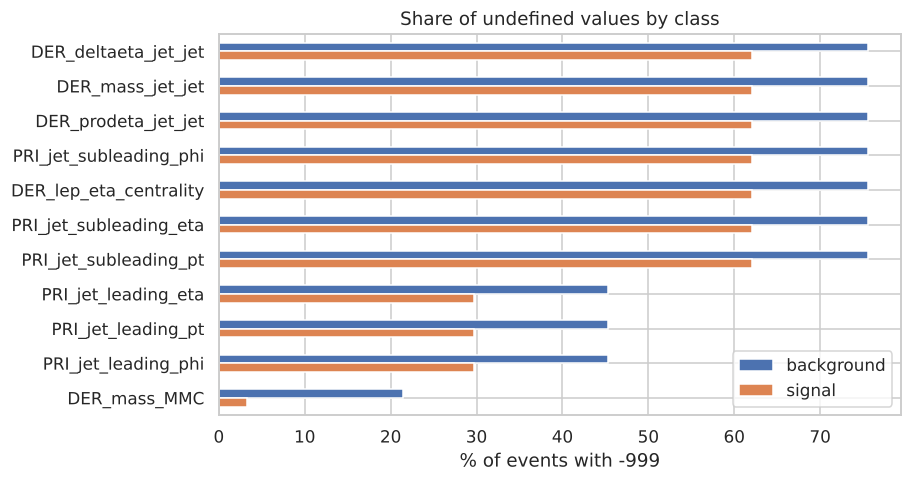

jet_jet mass undefined  False  True 
jet_num                             
0                           0  99913
1                           0  77544
2                       50379      0
3                       22164      0
leading jet pt undefined  False  True 
jet_num                               
0                             0  99913
1                         77544      0
2                         50379      0
3                         22164      0
DER_mass_MMC undefined by jet_num (%):
PRI_jet_num
0    26.1
1     9.8
2     5.9
3     6.7
Name: DER_mass_MMC, dtype: float64
Signal weight share when MMC undefined vs defined: 7e-05 vs 0.00234
Signal share of EVENTS when MMC undefined vs defined: 0.0744 vs 0.3909


In [5]:
miss = (X == hu.MISSING)
mt = pd.DataFrame({"all": miss.mean(), "background": miss[y==0].mean(), "signal": miss[y==1].mean()})
mt = mt[mt["all"] > 0].sort_values("all", ascending=False)
display((mt*100).round(1))
ax = (mt[["background","signal"]]*100).plot.barh(figsize=(8,4.5)); ax.invert_yaxis()
ax.set_xlabel("% of events with -999"); ax.set_title("Share of undefined values by class")
savefig("01_missing_by_class")
print(pd.crosstab(X.PRI_jet_num, miss["DER_mass_jet_jet"], rownames=["jet_num"], colnames=["jet_jet mass undefined"]))
print(pd.crosstab(X.PRI_jet_num, miss["PRI_jet_leading_pt"], rownames=["jet_num"], colnames=["leading jet pt undefined"]))
print("DER_mass_MMC undefined by jet_num (%):"); print((miss["DER_mass_MMC"].groupby(X.PRI_jet_num).mean()*100).round(1))
print("Signal weight share when MMC undefined vs defined:",
      round(w[(y==1)&miss["DER_mass_MMC"]].sum()/w[miss["DER_mass_MMC"]].sum(),5), "vs",
      round(w[(y==1)&~miss["DER_mass_MMC"]].sum()/w[~miss["DER_mass_MMC"]].sum(),5))
print("Signal share of EVENTS when MMC undefined vs defined:", round(y[miss["DER_mass_MMC"]].mean(),4), "vs", round(y[~miss["DER_mass_MMC"]].mean(),4))
RESULTS["missing_pct"] = (mt*100).round(2).to_dict()

**Interpretation.** Eleven features contain `-999`, and the pattern is structural, not random. All `*_jet_jet`, centrality and sub-leading-jet features are undefined for exactly the events with fewer than 2 jets (71 %), and the leading-jet features for events with 0 jets (40 %), as the cross-tables show: `-999` is a function of `PRI_jet_num`, so it carries information. `DER_mass_MMC` is undefined for 15 % of events, especially at 0 jets (26 %), and its missingness is related to the class: only 7.4 % of events with undefined MMC are signal, against 39.1 % when it is defined (by weight 0.007 % vs 0.234 %). Dropping these columns or replacing the marker blindly would throw that information away or invent measurements.

## 2. Exploratory data analysis

**Question 1:** counts and weights tell different stories — how different? How are weights distributed inside each class, and does the jet multiplicity matter?

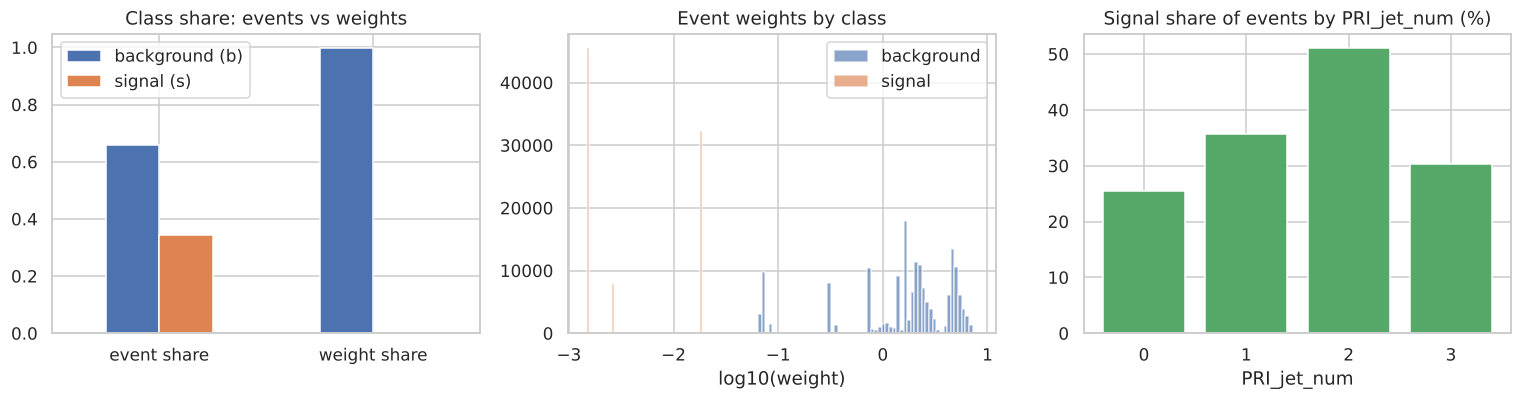

events per jet_num (share): {0: 0.4, 1: 0.31, 2: 0.202, 3: 0.089}
weight range background: 0.06406 - 7.823 | signal: 0.0015 - 0.01864


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
cls[["event share","weight share"]].T.plot.bar(ax=ax[0], rot=0, color=["#4c72b0","#dd8452"]); ax[0].set_title("Class share: events vs weights")
for c, name, col in [(0,"background","#4c72b0"),(1,"signal","#dd8452")]:
    ax[1].hist(np.log10(w[y==c]), bins=60, alpha=.65, label=name, color=col)
ax[1].set_xlabel("log10(weight)"); ax[1].set_title("Event weights by class"); ax[1].legend()
jn = pd.DataFrame({"jet_num": X.PRI_jet_num.astype(int), "y": y, "w": w})
sig_frac = jn.groupby("jet_num").y.mean()
ax[2].bar(sig_frac.index.astype(str), sig_frac.values*100, color="#55a868"); ax[2].set_title("Signal share of events by PRI_jet_num (%)"); ax[2].set_xlabel("PRI_jet_num")
plt.tight_layout(); savefig("02_class_weights_jets")
print("events per jet_num (share):", jn.groupby("jet_num").size().div(len(jn)).round(3).to_dict())
print("weight range background:", round(w[y==0].min(),5), "-", round(w[y==0].max(),3), "| signal:", round(w[y==1].min(),5), "-", round(w[y==1].max(),5))

**Interpretation.** Background weights range from 0.064 to 7.8 while signal weights are almost constant (0.0015–0.019), so a signal event carries roughly 100–1000 times less weight than a typical background event; the weighted problem is therefore dominated by background, even though signal events are a third of the rows. Event counts of 0, 1, 2 and 3 jets are 40 %, 31 %, 20 % and 9 %, and the signal fraction of events changes with jet multiplicity, so jet multiplicity is a meaningful sub-population variable.

**Question 2:** which features separate signal from background? Density plots, box plots and one carefully chosen scatter plot for the physically most meaningful variables (`-999` excluded from the plots).

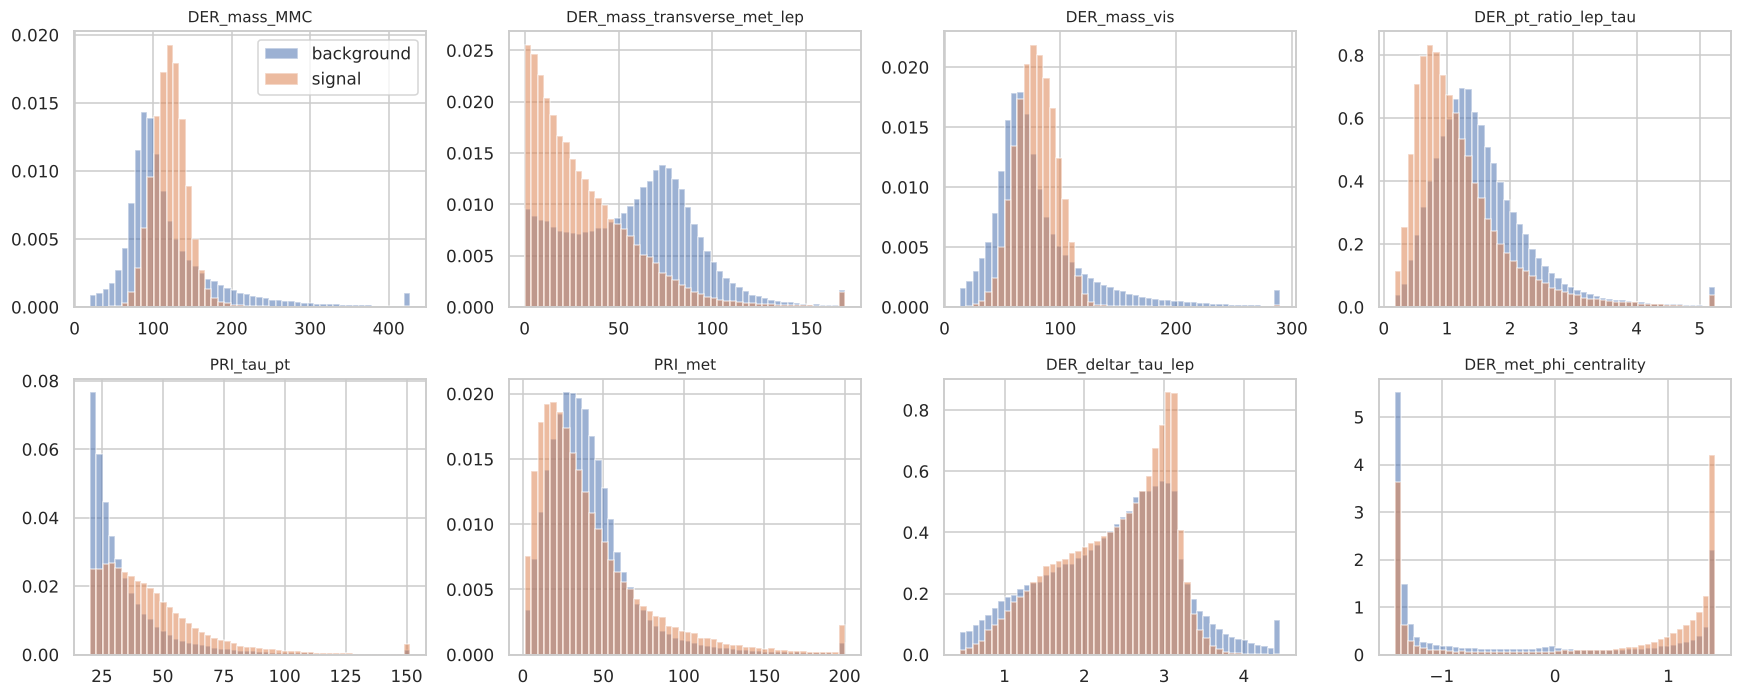

Single-feature separation (ROC-AUC, 0.5 = none):


,AUC
DER_mass_transverse_met_lep,0.737
PRI_tau_pt,0.692
DER_deltaeta_jet_jet,0.671
DER_lep_eta_centrality,0.668
DER_prodeta_jet_jet,0.665
DER_pt_ratio_lep_tau,0.662
DER_mass_jet_jet,0.652
DER_met_phi_centrality,0.639


Least separating:


,AUC
PRI_lep_phi,0.502
PRI_lep_eta,0.502
PRI_jet_subleading_eta,0.501
PRI_tau_eta,0.500
PRI_jet_leading_eta,0.500
PRI_jet_leading_phi,0.500


In [7]:
Xn = hu.to_nan(X)
cols = ["DER_mass_MMC","DER_mass_transverse_met_lep","DER_mass_vis","DER_pt_ratio_lep_tau","PRI_tau_pt","PRI_met","DER_deltar_tau_lep","DER_met_phi_centrality"]
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for a, c in zip(axes.ravel(), cols):
    lo, hi = Xn[c].quantile([.001, .995])
    for cl, name, col in [(0,"background","#4c72b0"),(1,"signal","#dd8452")]:
        a.hist(Xn.loc[y==cl, c].clip(lo, hi).dropna(), bins=50, density=True, alpha=.55, label=name, color=col)
    a.set_title(c, fontsize=10)
axes[0,0].legend(); plt.tight_layout(); savefig("03_feature_distributions")
sep = {}
for c in Xn.columns:
    m = Xn[c].notna(); a = roc_auc_score(y[m], Xn.loc[m, c]); sep[c] = max(a, 1-a)
sep = pd.Series(sep).sort_values(ascending=False)
print("Single-feature separation (ROC-AUC, 0.5 = none):"); display(sep.round(3).head(8).to_frame("AUC"))
print("Least separating:"); display(sep.round(3).tail(6).to_frame("AUC"))
RESULTS["single_feature_auc_top"] = sep.head(8).round(4).to_dict()

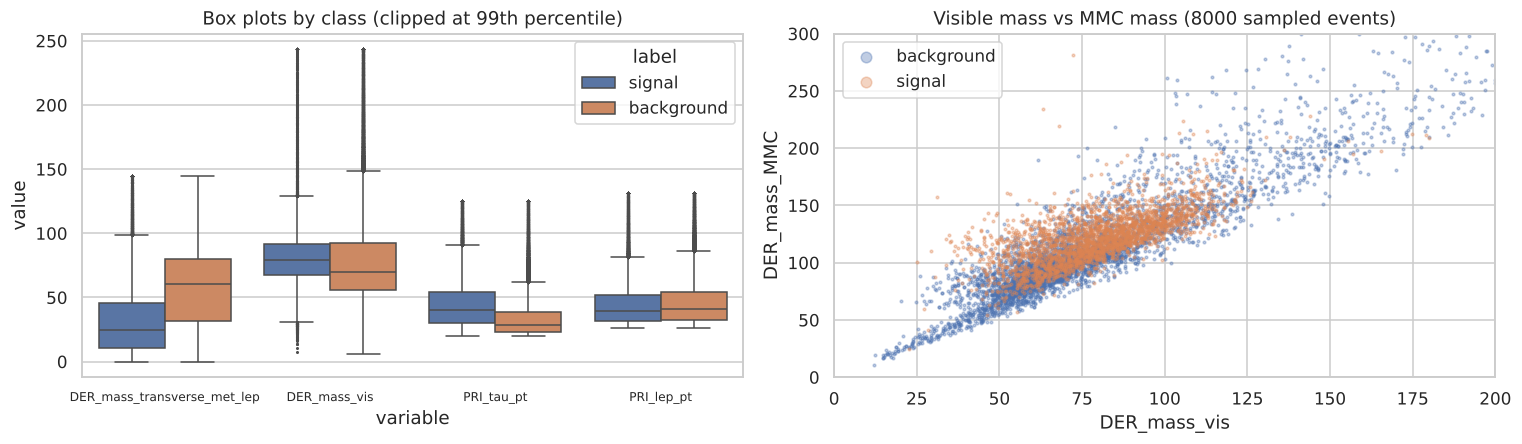

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
bx = pd.DataFrame({"label": np.where(y==1, "signal", "background")}).join(Xn[["DER_mass_transverse_met_lep","DER_mass_vis","PRI_tau_pt","PRI_lep_pt"]])
bxm = bx.melt(id_vars="label"); bxm["value"] = bxm.groupby("variable").value.transform(lambda s: s.clip(upper=s.quantile(.99)))
sns.boxplot(data=bxm, x="variable", y="value", hue="label", ax=ax[0], palette=["#4c72b0","#dd8452"], fliersize=1); ax[0].set_title("Box plots by class (clipped at 99th percentile)"); ax[0].tick_params(axis="x", labelsize=8)
sm = np.random.RandomState(SEED).choice(N, min(8000, N), replace=False); d_ = Xn.iloc[sm]
for cl, name, col in [(0,"background","#4c72b0"),(1,"signal","#dd8452")]:
    k = (y[sm]==cl) & d_.DER_mass_MMC.notna().to_numpy(); ax[1].scatter(d_.DER_mass_vis[k], d_.DER_mass_MMC[k], s=3, alpha=.35, label=name, color=col)
ax[1].set_xlim(0, 200); ax[1].set_ylim(0, 300); ax[1].set_xlabel("DER_mass_vis"); ax[1].set_ylabel("DER_mass_MMC"); ax[1].set_title("Visible mass vs MMC mass (8000 sampled events)"); ax[1].legend(markerscale=4)
plt.tight_layout(); savefig("03b_box_scatter")

**Interpretation.** Signal and background overlap strongly in every single variable, so no single cut will do. The best single-feature separators are `DER_mass_transverse_met_lep` (AUC 0.74), `PRI_tau_pt` (0.69) and the di-jet variables (about 0.65–0.67): signal events tend to have a smaller transverse mass and a harder tau. In the mass plot, the full-mass estimate `DER_mass_MMC` for signal peaks nearer the 125 GeV region and background has a broad Z-like bump at lower values, but both are wide, and background also has a long tail towards high mass. The transverse-mass plot shows signal piled up at low values while background has a second bump near 70–80 GeV. The scatter of `DER_mass_vis` against `DER_mass_MMC` shows the two are strongly related (Spearman 0.86 later) with class differences visible mainly in how the cloud is shifted. Combining variables is necessary; this motivates non-linear multivariate models.

**Question 3:** do azimuth angles (`*_phi`) carry information by themselves? Physics says rotation symmetry should make absolute `phi` uninformative, but angle *differences* may help.

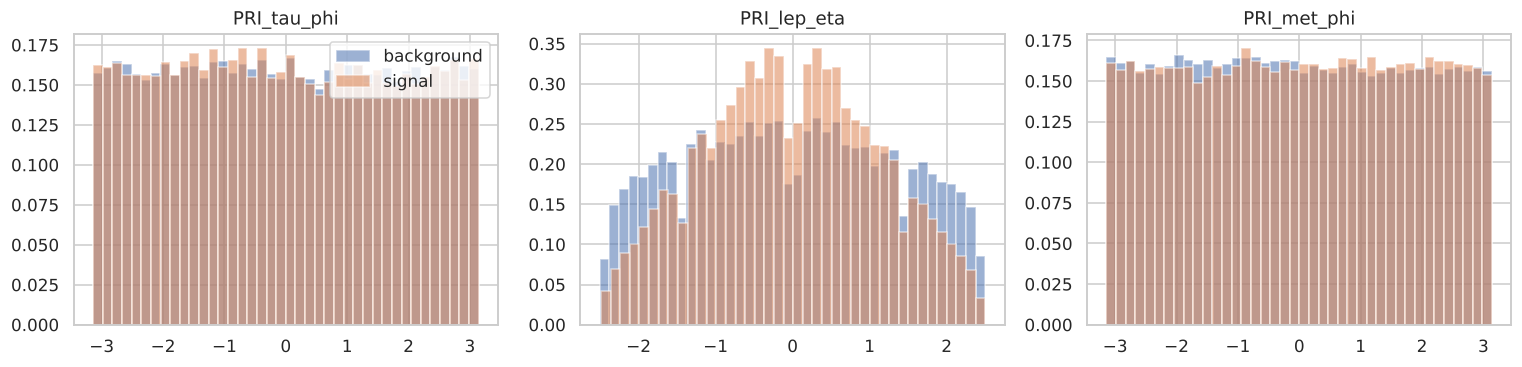

dphi_tau_lep   single-feature AUC = 0.570
dphi_tau_met   single-feature AUC = 0.504
dphi_lep_met   single-feature AUC = 0.718


PRI_tau_phi    single-feature AUC = 0.503
PRI_lep_phi    single-feature AUC = 0.502
PRI_met_phi    single-feature AUC = 0.505


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for a, c in zip(axes, ["PRI_tau_phi","PRI_lep_eta","PRI_met_phi"]):
    for cl, name, col in [(0,"background","#4c72b0"),(1,"signal","#dd8452")]:
        a.hist(Xn.loc[y==cl, c].dropna(), bins=40, density=True, alpha=.55, label=name, color=col)
    a.set_title(c)
axes[0].legend(); plt.tight_layout(); savefig("04_phi_eta")
Fx = hu.add_features(X)
for c in ["dphi_tau_lep","dphi_tau_met","dphi_lep_met"]:
    a = roc_auc_score(y, Fx[c]); print(f"{c:14s} single-feature AUC = {max(a,1-a):.3f}")
for c in ["PRI_tau_phi","PRI_lep_phi","PRI_met_phi"]:
    a = roc_auc_score(y, Xn[c]); print(f"{c:14s} single-feature AUC = {max(a,1-a):.3f}")

**Interpretation.** As expected from the rotation symmetry of the detector, absolute azimuth angles are essentially useless alone (single-feature AUC 0.50–0.51) and their distributions are flat. Angle *differences* behave differently: |Δφ(lepton, MET)| reaches AUC 0.72 on its own, |Δφ(tau, lepton)| 0.57, and |Δφ(tau, MET)| 0.50. This motivates engineered angle-difference features and a 'drop raw φ' experiment later.

**Question 4:** which features carry related information? (Spearman correlation among defined values; many features are heavy-tailed.)

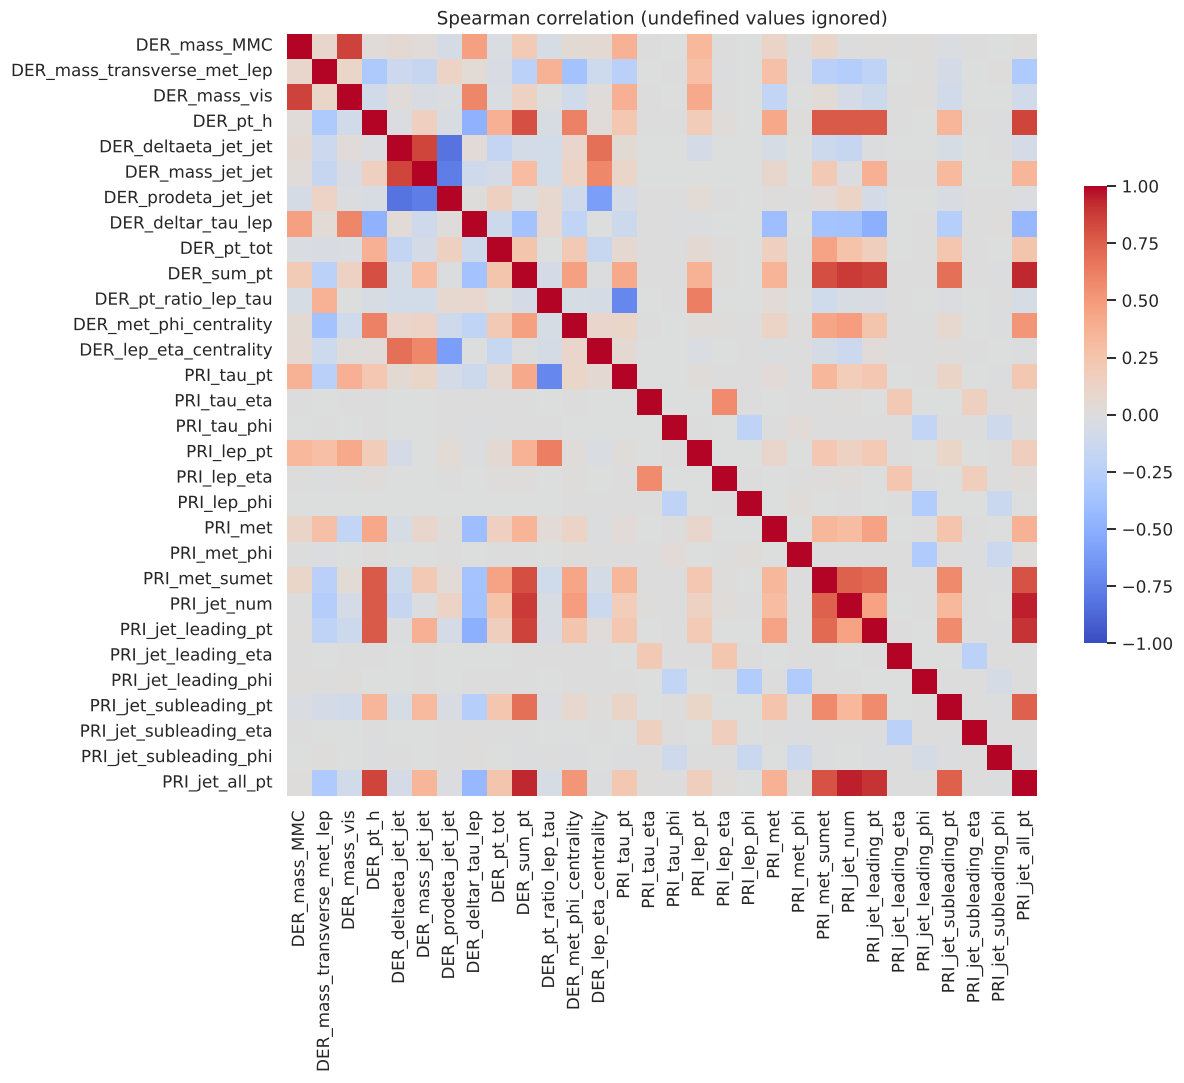

rho
PRI_jet_num          PRI_jet_all_pt       0.949
DER_sum_pt           PRI_jet_all_pt       0.930
PRI_jet_leading_pt   PRI_jet_all_pt       0.906
DER_sum_pt           PRI_jet_num          0.876
                     PRI_jet_leading_pt   0.857
DER_mass_MMC         DER_mass_vis         0.855
DER_pt_h             PRI_jet_all_pt       0.849
DER_deltaeta_jet_jet DER_mass_jet_jet     0.848
                     DER_prodeta_jet_jet -0.820
DER_sum_pt           PRI_met_sumet        0.820
DER_pt_h             DER_sum_pt           0.805

In [10]:
corr = Xn.corr(method="spearman", min_periods=1000)
plt.figure(figsize=(11, 9)); sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, xticklabels=True, yticklabels=True, cbar_kws={"shrink": .6})
plt.title("Spearman correlation (undefined values ignored)"); savefig("05_correlation")
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().rename("rho")
top = pairs[pairs.abs() > 0.8].sort_values(key=abs, ascending=False)
display(top.round(3).to_frame()); RESULTS["high_corr_pairs"] = {f"{a} | {b}": float(v) for (a, b), v in top.round(3).items()}

**Interpretation.** Strong correlations appear in physically explainable groups: the jet-activity group (`PRI_jet_num`, `PRI_jet_all_pt`, `DER_sum_pt`, `PRI_jet_leading_pt`, `DER_pt_h`; ρ up to 0.95), the mass group (`DER_mass_MMC` with `DER_mass_vis`, 0.86), and the di-jet group (`DER_mass_jet_jet`, `DER_deltaeta_jet_jet`, `DER_prodeta_jet_jet`). Correlated groups mean permutation importance will be shared inside a group, and that no feature should be removed just because it correlates with another one: derived features contain information the primitive ones only encode implicitly, which we test later rather than assume.

## 3. Preprocessing decisions and validation design
* `EventId`, `Weight`, `Label` are kept out of the feature matrix. `Weight` is used only for evaluation and (in some experiments) as `sample_weight`.
* Learned preprocessing (imputers, scalers, one-hot encoders) lives inside `Pipeline` / `ColumnTransformer` objects and is fitted on training data only. Scaling is applied only for Logistic Regression; tree models do not need it.
* `PRI_jet_num` is an integer count (0, 1, 2, 3) that behaves like a category, so Logistic Regression one-hot encodes it; all other columns are scaled continuous measurements.
* `-999` strategies compared below: keep as a number, convert to NaN (native for boosting), median imputation, median imputation plus missing-indicators.
* **Validation:** one stratified 80/20 split (seed 42) used for every model comparison, then stratified 5-fold CV for the finalists. The test file is never used for a decision.
* **Weights in validation:** a 20 % split carries 1/5 of the total weight, so validation weights are multiplied by `N_train / N_val` (= 5). AMS is then on the same scale as the full-data AMS used in the competition (weights sum to the same totals).
* **AMS threshold:** we do not use `p > 0.5`; we choose the *fraction of events called signal* (top-scoring events) that maximises AMS, using validation / out-of-fold data only.

In [11]:
idx = np.arange(N)
tr_idx, va_idx = train_test_split(idx, test_size=0.2, stratify=y, random_state=SEED)
Xtr, ytr, wtr = X.iloc[tr_idx], y[tr_idx], w[tr_idx]
Xva, yva, wva_raw = X.iloc[va_idx], y[va_idx], w[va_idx]
SCALE = N / len(va_idx); wva = wva_raw * SCALE
print(f"train {len(tr_idx)}  val {len(va_idx)}  | signal share train {ytr.mean():.4f} val {yva.mean():.4f} | validation weight scale = {SCALE:.1f}")

# --- verify our AMS against the competition's reference implementation (verbatim formula of the Python-2 file) ---
import math
def ref_AMS(s, b):
    br = 10.0
    radicand = 2 * ((s + b + br) * math.log(1.0 + s / (b + br)) - s)
    return math.sqrt(radicand)
rng = np.random.RandomState(0)
diffs = [abs(ref_AMS(s_, b_) - float(hu.ams(s_, b_))) for s_, b_ in zip(rng.uniform(0.1, 700, 200), rng.uniform(1, 2e5, 200))]
print("max |reference - ours| over 200 random (s, b):", max(diffs))
pred = (np.random.RandomState(1).rand(len(yva)) < 0.2).astype(int)   # explicit event loop, as in the reference file
s_ = sum(wva[i] for i in range(len(yva)) if pred[i] == 1 and yva[i] == 1)
b_ = sum(wva[i] for i in range(len(yva)) if pred[i] == 1 and yva[i] == 0)
print("reference-style AMS:", ref_AMS(s_, b_), "| ours:", hu.ams_from_labels(yva, pred, wva))

train 200000  val 50000  | signal share train 0.3427 val 0.3427 | validation weight scale = 5.0
max |reference - ours| over 200 random (s, b): 1.867833739239988e-09
reference-style AMS: 0.48212337435965225 | ours: 0.4821233743422027


**Interpretation.** The vectorised AMS used throughout agrees with the formula of the competition reference file to 2×10⁻⁹, and an explicit event-by-event computation in the style of the reference code gives the same number as our `ams_from_labels`. The reference file is Python 2, so its formula was re-typed in Python 3 for this check instead of imported directly.

### Helper functions: scoring and the experiment table

In [12]:
EXP = []   # experiment table
def evaluate(score, y_, w_, prob=True):
    out = {"AUC": roc_auc_score(y_, score), "wAUC": roc_auc_score(y_, score, sample_weight=w_)}
    out["Acc@0.5"] = accuracy_score(y_, score > 0.5) if prob else np.nan
    out["AMS@0.5"] = hu.ams_from_labels(y_, (score > 0.5).astype(int), w_) if prob else np.nan
    b = hu.best_threshold(y_, score, w_)
    out["AMS_best"], out["frac_signal"], out["thr"] = b["ams"], b["frac"], b["thr"]
    return out
def log_exp(name, prep, model, weights, change, score, prob=True):
    r = evaluate(score, yva, wva, prob)
    EXP.append({"Experiment": name, "Preprocessing": prep, "Model": model, "Training weights": weights,
                **{k: r[k] for k in ["AUC","wAUC","Acc@0.5","AMS@0.5","AMS_best","frac_signal"]}, "What changed?": change})
    return r
def fit_score(pipe, Xa, ya, Xb, sw=None, name="clf"):
    t = time.time()
    if sw is None: pipe.fit(Xa, ya)
    else: pipe.fit(Xa, ya, **{f"{name}__sample_weight": sw})
    return pipe.predict_proba(Xb)[:, 1], time.time() - t
def best_of(score): return hu.best_threshold(yva, score, wva)
W_BAL = hu.class_balanced_weights(ytr, wtr)     # class-balanced weights, computed from training rows only
nan_tf = lambda: FunctionTransformer(hu.to_nan)
CONT = [c for c in X.columns if c != "PRI_jet_num"]

## 4. Baselines
Reference points: (a) call every event signal, (b) random labels drawn with the class prior, (c) Logistic Regression.

In [13]:
dummy = DummyClassifier(strategy="stratified", random_state=SEED).fit(Xtr, ytr)
dpred = dummy.predict(Xva); d_ams = hu.ams_from_labels(yva, dpred, wva)
all_sig = hu.ams_from_labels(yva, np.ones_like(yva), wva)
EXP.append({"Experiment":"B0a","Preprocessing":"none","Model":"Dummy (all signal)","Training weights":"-","AUC":0.5,"wAUC":0.5,"Acc@0.5":accuracy_score(yva, np.ones_like(yva)),"AMS@0.5":all_sig,"AMS_best":all_sig,"frac_signal":1.0,"What changed?":"trivial reference"})
EXP.append({"Experiment":"B0b","Preprocessing":"none","Model":"Dummy (stratified random)","Training weights":"-","AUC":0.5,"wAUC":0.5,"Acc@0.5":accuracy_score(yva, dpred),"AMS@0.5":d_ams,"AMS_best":d_ams,"frac_signal":dpred.mean(),"What changed?":"random labels with class prior"})
print(f"all-signal AMS = {all_sig:.3f} (accuracy {accuracy_score(yva, np.ones_like(yva)):.3f}) | random labels AMS = {d_ams:.3f}")
RESULTS["baselines"] = {"all_signal_ams": all_sig, "random_ams": d_ams}

all-signal AMS = 1.084 (accuracy 0.343) | random labels AMS = 0.624


In [14]:
def lr_pipe(indicator=True, C=1.0):
    num = Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=indicator)), ("sc", StandardScaler())])
    ct = ColumnTransformer([("jet", OneHotEncoder(handle_unknown="ignore"), ["PRI_jet_num"]), ("num", num, CONT)])
    return Pipeline([("nan", nan_tf()), ("prep", ct), ("clf", LogisticRegression(C=C, max_iter=500))])
sc_lr, t = fit_score(lr_pipe(), Xtr, ytr, Xva)
r = log_exp("B1", "NaN -> median + indicators, StandardScaler, one-hot jet_num", "LogisticRegression", "none", "linear baseline", sc_lr)
print({k: round(v, 4) for k, v in r.items()}, f"fit {t:.1f}s")

{'AUC': 0.8152, 'wAUC': 0.8811, 'Acc@0.5': 0.7512, 'AMS@0.5': 2.0174, 'AMS_best': 2.0759, 'frac_signal': 0.325, 'thr': 0.4481} fit 2.2s


**Interpretation.** Logistic Regression reaches ROC-AUC 0.815 and best AMS 2.08 — about twice the 'all signal' reference (1.08) and far above random labels (0.62). It is a sensible interpretable baseline, but a linear boundary cannot capture the structure that the tree models exploit below.

## 5. Experiments on the `-999` marker
**Question:** how should undefined values be treated? Compared with HistGradientBoosting (same split, same settings, class-balanced weights) and with Logistic Regression.

In [15]:
def hgb(**kw):
    p = dict(max_iter=400, learning_rate=0.08, max_leaf_nodes=31, early_stopping=True, validation_fraction=0.1, n_iter_no_change=20, random_state=SEED)
    p.update(kw); return HistGradientBoostingClassifier(**p)
HGB_PREP = {
 "A: keep -999 as a number": lambda: Pipeline([("clf", hgb())]),
 "B: -999 -> NaN (native missing support)": lambda: Pipeline([("nan", nan_tf()), ("clf", hgb())]),
 "C: -999 -> median": lambda: Pipeline([("nan", nan_tf()), ("imp", SimpleImputer(strategy="median")), ("clf", hgb())]),
 "D: -999 -> median + indicators": lambda: Pipeline([("nan", nan_tf()), ("imp", SimpleImputer(strategy="median", add_indicator=True)), ("clf", hgb())]),
}
miss_scores = {}
for k, mk in HGB_PREP.items():
    s_, t = fit_score(mk(), Xtr, ytr, Xva, sw=W_BAL); miss_scores[k] = s_
    r = log_exp("M-" + k[0], k[3:], "HistGradientBoosting", "class-balanced", "missing-value strategy", s_)
    print(f"{k:42s} AUC {r['AUC']:.4f}  AMS_best {r['AMS_best']:.3f}  ({t:.0f}s)")
sc_lr_nomi, _ = fit_score(lr_pipe(indicator=False), Xtr, ytr, Xva)
r = log_exp("M-LR", "median imputation, no indicators", "LogisticRegression", "none", "drop the indicators from B1", sc_lr_nomi)
r1 = [e for e in EXP if e["Experiment"] == "B1"][0]
print(f"LR median only       AUC {r['AUC']:.4f}  AMS {r['AMS_best']:.3f}"); print(f"LR median+indicator  AUC {r1['AUC']:.4f}  AMS {r1['AMS_best']:.3f}")

A: keep -999 as a number                   AUC 0.8972  AMS_best 3.560  (24s)


B: -999 -> NaN (native missing support)    AUC 0.8971  AMS_best 3.555  (21s)


C: -999 -> median                          AUC 0.8970  AMS_best 3.553  (25s)


D: -999 -> median + indicators             AUC 0.8968  AMS_best 3.494  (26s)


LR median only       AUC 0.8146  AMS 2.074
LR median+indicator  AUC 0.8152  AMS 2.076


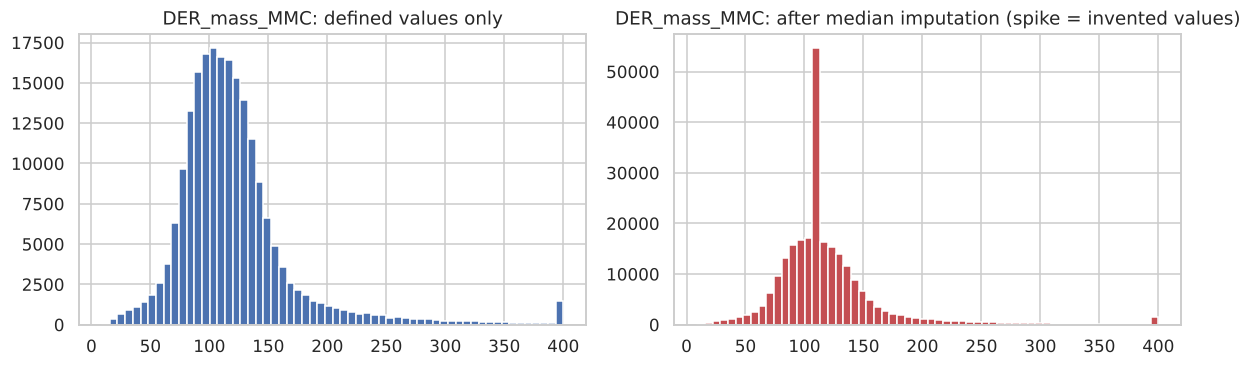

In [16]:
c = "DER_mass_MMC"
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(Xn.loc[Xn[c].notna(), c].clip(0, 400), bins=60, color="#4c72b0"); ax[0].set_title(f"{c}: defined values only")
ax[1].hist(Xn[c].fillna(Xn[c].median()).clip(0, 400), bins=60, color="#c44e52"); ax[1].set_title(f"{c}: after median imputation (spike = invented values)")
plt.tight_layout(); savefig("06_imputation_effect")

**Interpretation.** For HistGradientBoosting the four strategies are almost indistinguishable in ranking quality (AUC 0.8968–0.8972): keeping `-999` as a number (AMS 3.560), NaN with native handling (3.555) and median imputation (3.553) agree within noise, and adding missing-indicators did not help (3.495, slightly worse). The model can already infer undefinedness from `PRI_jet_num` and from the sentinel position, so the choice matters little for boosting; we use native NaN handling because it is the cleanest and needs no invented values. For Logistic Regression the indicators also add almost nothing (AUC 0.8152 vs 0.8146). The histogram shows why median imputation can be misleading in principle: it creates an artificial spike of 'events' at the median that is not a measurement, which a linear model or a distance-based method would treat as real.

## 6. Experiments with event weights
**Question:** should the model be trained with `sample_weight`? Three schemes on the same model: none, raw `Weight`, class-balanced weights (signal and background get equal total weight; relative weights inside each class are kept).

In [17]:
WS = {"none": None, "raw Weight": wtr, "class-balanced": W_BAL}
w_scores = {}
for k, sw in WS.items():
    s_, t = fit_score(Pipeline([("nan", nan_tf()), ("clf", hgb())]), Xtr, ytr, Xva, sw=sw); w_scores[k] = s_
    r = log_exp("W-" + k.split()[0], "-999 -> NaN", "HistGradientBoosting", k, "training weights", s_)
    print(f"{k:15s} AUC {r['AUC']:.4f}  wAUC {r['wAUC']:.4f}  AMS@0.5 {r['AMS@0.5']:.3f}  AMS_best {r['AMS_best']:.3f}  frac {r['frac_signal']:.3f}")
best_w = max(w_scores, key=lambda k: best_of(w_scores[k])["ams"]); print("best weighting scheme on validation:", best_w)
RESULTS["best_weight_scheme"] = best_w

none            AUC 0.9093  wAUC 0.9284  AMS@0.5 2.860  AMS_best 3.502  frac 0.150


raw Weight      AUC 0.8572  wAUC 0.9108  AMS@0.5 1.619  AMS_best 3.153  frac 0.165


class-balanced  AUC 0.8971  wAUC 0.9331  AMS@0.5 2.362  AMS_best 3.555  frac 0.165
best weighting scheme on validation: class-balanced


**Interpretation.** Weighting changes what the model optimises. Unweighted training gives the highest accuracy (0.841) and AUC (0.909) but the AMS at the best cut is lower (3.50): it learns the event-count problem. Raw `Weight` as `sample_weight` is clearly worst (AMS 3.15, AUC 0.857): signal weights are ~1000× smaller than the heavy background weights, so the model almost ignores signal. Class-balanced weights (equal total weight per class, relative weights kept) give the best AMS (3.56) and the best weighted AUC (0.933, against 0.928 unweighted and 0.911 raw), which is the quantity closest to the metric. The metrics disagree about which model is 'best', which is exactly the warning in the guidelines: select by weighted AMS, not accuracy.

## 7. Model comparison (same split, same preprocessing rules)
Logistic Regression, Decision Tree, Random Forest, Extra Trees, HistGradientBoosting, XGBoost, LightGBM. Weighting scheme: the winner of the experiment above (Logistic Regression is trained without weights, as in the baseline).

In [18]:
SW = {"none": None, "raw Weight": wtr, "class-balanced": W_BAL}[best_w]
n_est = 60 if QUICK else 300
XGB = lambda: xgb.XGBClassifier(n_estimators=n_est, learning_rate=0.08, max_depth=6, subsample=0.8, colsample_bytree=0.8, tree_method="hist", n_jobs=-1, random_state=SEED)
LGB = lambda: lgb.LGBMClassifier(n_estimators=n_est, learning_rate=0.08, num_leaves=31, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, n_jobs=-1, random_state=SEED, verbose=-1)
MODELS = {
 "Logistic Regression": (lr_pipe(), "NaN->median+indicators, scaled"),
 "Decision Tree": (Pipeline([("clf", DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, random_state=SEED))]), "-999 kept"),
 "Random Forest": (Pipeline([("clf", RandomForestClassifier(n_estimators=40 if QUICK else 100, max_depth=14, min_samples_leaf=30, max_samples=0.5, n_jobs=-1, random_state=SEED))]), "-999 kept"),
 "Extra Trees": (Pipeline([("clf", ExtraTreesClassifier(n_estimators=40 if QUICK else 200, max_depth=18, min_samples_leaf=20, n_jobs=-1, random_state=SEED))]), "-999 kept"),
 "HistGradientBoosting": (Pipeline([("nan", nan_tf()), ("clf", hgb())]), "-999 -> NaN"),
 "XGBoost": (Pipeline([("nan", nan_tf()), ("clf", XGB())]), "-999 -> NaN"),
 "LightGBM": (Pipeline([("nan", nan_tf()), ("clf", LGB())]), "-999 -> NaN"),
}
model_scores, model_times = {}, {}
for i, (name, (pipe, prep)) in enumerate(MODELS.items()):
    sw = None if name == "Logistic Regression" else SW
    s_, t = fit_score(pipe, Xtr, ytr, Xva, sw=sw); model_scores[name] = s_; model_times[name] = t
    r = log_exp(f"MOD-{i+1}", prep, name, "none" if sw is None else best_w, "model family", s_)
    print(f"{name:22s} AUC {r['AUC']:.4f}  AMS@0.5 {r['AMS@0.5']:.3f}  AMS_best {r['AMS_best']:.3f}  frac {r['frac_signal']:.3f}  ({t:.0f}s)")
RESULTS["fit_seconds"] = {k: round(v, 1) for k, v in model_times.items()}

Logistic Regression    AUC 0.8152  AMS@0.5 2.017  AMS_best 2.076  frac 0.325  (2s)


Decision Tree          AUC 0.8699  AMS@0.5 2.114  AMS_best 2.790  frac 0.240  (4s)


Random Forest          AUC 0.8864  AMS@0.5 2.297  AMS_best 3.391  frac 0.125  (33s)


Extra Trees            AUC 0.8612  AMS@0.5 2.142  AMS_best 3.007  frac 0.195  (36s)


HistGradientBoosting   AUC 0.8971  AMS@0.5 2.362  AMS_best 3.555  frac 0.165  (21s)


XGBoost                AUC 0.9004  AMS@0.5 2.402  AMS_best 3.619  frac 0.165  (11s)


LightGBM               AUC 0.8987  AMS@0.5 2.390  AMS_best 3.595  frac 0.155  (8s)


**Interpretation.** Gradient boosting wins clearly: XGBoost (AMS 3.62), LightGBM (3.60) and HistGradientBoosting (3.56) are close to each other, Random Forest is next (3.39), then Extra Trees (3.01), a single Decision Tree (2.79) and Logistic Regression (2.08). The jump from linear to tree-based models (+1.3 AMS) shows that non-linear interactions matter; boosting beats bagging here. Differences of about 0.05 between the three boosters are within the noise measured by cross-validation later, so we do not claim a winner from one split. Boosters also trained fastest (8–22 s) versus 33–36 s for the forests on one CPU core.

## 8. Accuracy vs ROC-AUC vs AMS
**Question:** does a model that is better in accuracy or AUC also win on AMS? Does the default 0.5 threshold work?

,Model,AUC,Acc@0.5,AMS@0.5,AMS_best,frac_signal
Experiment,,,,,,
MOD-1,Logistic Regression,0.8152,0.7512,2.0174,2.0759,0.325
MOD-2,Decision Tree,0.8699,0.7567,2.1137,2.7904,0.240
MOD-3,Random Forest,0.8864,0.7727,2.2971,3.3908,0.125
MOD-4,Extra Trees,0.8612,0.7284,2.1420,3.0074,0.195
MOD-5,HistGradientBoosting,0.8971,0.7909,2.3624,3.5552,0.165
MOD-6,XGBoost,0.9004,0.7983,2.4016,3.6192,0.165
MOD-7,LightGBM,0.8987,0.7946,2.3903,3.5952,0.155
B0a,Dummy (all signal),0.5000,0.3427,1.0840,1.0840,1.000


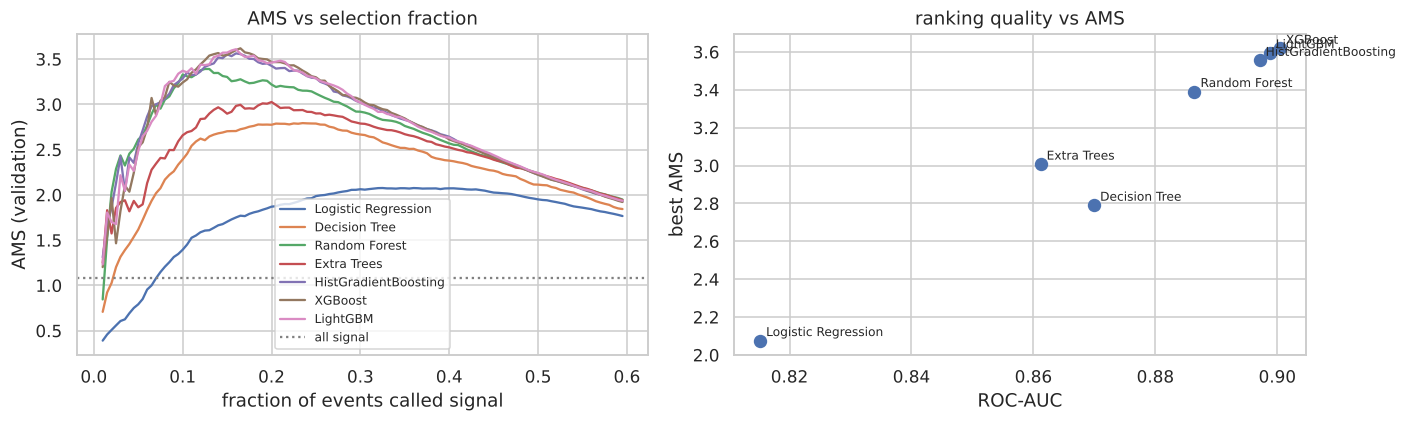

In [19]:
cmp = pd.DataFrame(EXP).set_index("Experiment").loc[[f"MOD-{i}" for i in range(1, 8)] + ["B0a"], ["Model","AUC","Acc@0.5","AMS@0.5","AMS_best","frac_signal"]]
display(cmp.round(4))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, s_ in model_scores.items():
    cv_, _ = hu.ams_curve(yva, s_, wva); ax[0].plot(hu.FRACS, cv_, label=name)
ax[0].axhline(all_sig, color="grey", ls=":", label="all signal"); ax[0].set_xlabel("fraction of events called signal"); ax[0].set_ylabel("AMS (validation)"); ax[0].set_title("AMS vs selection fraction"); ax[0].legend(fontsize=8)
m = cmp.iloc[:7]; ax[1].scatter(m.AUC, m.AMS_best, s=60)
for n_, r_ in m.iterrows(): ax[1].annotate(r_.Model, (r_.AUC, r_.AMS_best), fontsize=8, xytext=(4, 3), textcoords="offset points")
ax[1].set_xlabel("ROC-AUC"); ax[1].set_ylabel("best AMS"); ax[1].set_title("ranking quality vs AMS"); plt.tight_layout(); savefig("07_ams_vs_fraction_auc")
RESULTS["auc_vs_ams_rank_corr"] = float(pd.Series(m.AUC.values).corr(pd.Series(m.AMS_best.values), method="spearman"))

**Interpretation.** Ranking quality and AMS broadly agree across model families (Spearman correlation 0.96 between AUC and best AMS across the seven models), but AMS cares about one region of the ranking: the top ≈ 15 % of events, where signal purity matters. The default 0.5 threshold is poor: for HistGradientBoosting the AMS at p > 0.5 is 2.36, while the best fraction (top 16.5 %) gives 3.56. Accuracy at 0.5 (0.79) says little about this. A model can rank well overall (high AUC) and still need a carefully chosen cut — and the weighting experiment above showed the converse too: the highest-AUC unweighted model is not the best AMS model.

## 9. Feature experiments
**Engineered features** (stateless, so no leakage; based on the physics of the decay): absolute azimuth differences between tau, lepton and missing energy (rotation-invariant); tau–lepton pseudorapidity gap; MET ratios; mass ratios and differences (visible mass vs the full MMC estimate: Z→ττ sits near 91 GeV, Higgs near 125 GeV); `p_T` balance ratios; sub-leading/leading jet ratio.
**Subset experiments:** drop raw `phi` angles; keep only the top 10 / top 20 of the 30 raw features by permutation importance (importance measured on an *inner* split of the training data, never on validation), compared with the full base feature set.

In [20]:
def hgb_pipe(featfn=None):
    steps = [("feat", FunctionTransformer(featfn))] if featfn else [("nan", nan_tf())]
    return Pipeline(steps + [("clf", hgb())])
FE = {"F0 base features": None, "F1 + engineered features": hu.add_features,
      "F2 base - raw phi": lambda a: hu.drop_raw_phi(hu.to_nan(a)), "F3 engineered - raw phi": hu.add_features_no_phi}
fe_scores = {}
for k, fn in FE.items():
    s_, t = fit_score(hgb_pipe(fn), Xtr, ytr, Xva, sw=SW); fe_scores[k] = s_
    r = log_exp("FE-" + k[:2], k[3:], "HistGradientBoosting", best_w, "feature set", s_)
    print(f"{k:28s} AUC {r['AUC']:.4f}  AMS_best {r['AMS_best']:.3f}  ({t:.0f}s)")

F0 base features             AUC 0.8971  AMS_best 3.555  (22s)


F1 + engineered features     AUC 0.8970  AMS_best 3.534  (29s)


F2 base - raw phi            AUC 0.8972  AMS_best 3.572  (18s)


F3 engineered - raw phi      AUC 0.8975  AMS_best 3.523  (27s)


In [21]:
itr, iva = train_test_split(np.arange(len(ytr)), test_size=0.2, stratify=ytr, random_state=SEED)
SW_in = None if SW is None else (W_BAL if best_w == "class-balanced" else wtr)
inner = hgb_pipe(None); inner.fit(Xtr.iloc[itr], ytr[itr], **({} if SW_in is None else {"clf__sample_weight": SW_in[itr]}))
pi_inner = permutation_importance(inner, Xtr.iloc[iva], ytr[iva], scoring="roc_auc", n_repeats=3, random_state=SEED, n_jobs=1)
feat_names = Xtr.columns   # permutation importance is measured on the 30 raw input columns
imp_inner = pd.Series(pi_inner.importances_mean, index=feat_names).sort_values(ascending=False)
def subset_fn(cols): return lambda a: hu.to_nan(a)[cols]
for k in (10, 20):
    s_, t = fit_score(hgb_pipe(subset_fn(list(imp_inner.index[:k]))), Xtr, ytr, Xva, sw=SW); fe_scores[f"top{k}"] = s_
    r = log_exp(f"FS-top{k}", f"base features, top {k} of 30 by inner permutation importance", "HistGradientBoosting", best_w, "feature subset", s_)
    print(f"top {k:2d} features  AUC {r['AUC']:.4f}  AMS_best {r['AMS_best']:.3f}")
print("features dropped in the top-20 subset:", list(imp_inner.index[20:]))
fe_auc_gain = roc_auc_score(yva, fe_scores["F1 + engineered features"]) - roc_auc_score(yva, fe_scores["F0 base features"])
fe_ams_gain = best_of(fe_scores["F1 + engineered features"])["ams"] - best_of(fe_scores["F0 base features"])["ams"]
USE_FE = bool(fe_auc_gain > 0 and fe_ams_gain >= 0)
print(f"engineered vs base: AUC {fe_auc_gain:+.4f}, AMS {fe_ams_gain:+.3f} -> use engineered features in the final pipeline: {USE_FE}")
RESULTS.update({"use_fe": USE_FE, "fe_auc_gain": fe_auc_gain, "fe_ams_gain": fe_ams_gain})

top 10 features  AUC 0.8931  AMS_best 3.380


top 20 features  AUC 0.8972  AMS_best 3.509
features dropped in the top-20 subset: ['PRI_lep_pt', 'DER_deltaeta_jet_jet', 'PRI_jet_leading_phi', 'PRI_met_phi', 'PRI_jet_num', 'PRI_lep_phi', 'PRI_tau_phi', 'DER_prodeta_jet_jet', 'PRI_jet_subleading_phi', 'PRI_jet_subleading_pt']
engineered vs base: AUC -0.0001, AMS -0.022 -> use engineered features in the final pipeline: False


**Interpretation.** On the validation split the engineered features did not help (AUC −0.0001, AMS −0.02), dropping raw φ was neutral (AMS 3.572, AUC 0.8972, +0.017), and engineered features without raw φ were also neutral. Reducing to the 20 most important of the 30 raw features gave AMS 3.509 (slightly worse), and to 10 features 3.380 (clearly worse): fewer features did not mean a better model, and the dropped ones included jet-subleading features and several φ angles. The cross-validation in the next sections re-tests the engineered features across five splits. Boosted trees can build ratios and differences themselves, which explains the small gain.

## 10. Further experiments: per-jet-group models and a small ensemble
**Per-jet-group model:** the pattern of undefined features is fixed by `PRI_jet_num` (0, 1, ≥2 jets), so each group is effectively a different problem. One model per group; scores are combined.
**Ensemble:** mean of rank-normalised scores of HistGradientBoosting, XGBoost and LightGBM, tried only after the individual models are strong.

In [22]:
FEAT = hu.add_features if USE_FE else hu.to_nan
grp = lambda d: np.minimum(d.PRI_jet_num.to_numpy().astype(int), 2)
gtr, gva = grp(Xtr), grp(Xva)
s_grp = np.zeros(len(yva)); t0 = time.time()
for g in (0, 1, 2):
    mk = gtr == g
    ok = list(FEAT(Xtr[mk]).columns[FEAT(Xtr[mk]).notna().any().to_numpy()])      # drop columns that are undefined for the whole group
    m = hgb_pipe(lambda a, ok=ok: FEAT(a)[ok])
    wg = {"none": None, "raw Weight": wtr[mk], "class-balanced": hu.class_balanced_weights(ytr[mk], wtr[mk])}[best_w]
    m.fit(Xtr[mk], ytr[mk], **({} if wg is None else {"clf__sample_weight": wg}))
    s_grp[gva == g] = m.predict_proba(Xva[gva == g])[:, 1]
r = log_exp("G-1", "per jet group (0, 1, >=2)", "HistGradientBoosting x3", best_w + " (per group)", "separate model per PRI_jet_num group", s_grp)
base_key = "F1 + engineered features" if USE_FE else "F0 base features"
print(f"per-group AUC {r['AUC']:.4f} AMS_best {r['AMS_best']:.3f}  vs single model AUC {roc_auc_score(yva, fe_scores[base_key]):.4f} AMS_best {best_of(fe_scores[base_key])['ams']:.3f} ({time.time()-t0:.0f}s)")

per-group AUC 0.8982 AMS_best 3.355  vs single model AUC 0.8971 AMS_best 3.555 (21s)


In [23]:
rk = lambda s_: rankdata(s_) / len(s_)
def make_gb(kind):
    clf = {"HGB": hgb, "XGB": XGB, "LGB": LGB}[kind]()
    return Pipeline([("feat", FunctionTransformer(FEAT)), ("clf", clf)])
ens_scores = {}
for kind in ("HGB", "XGB", "LGB"):
    ens_scores[kind], t = fit_score(make_gb(kind), Xtr, ytr, Xva, sw=SW)
    r = log_exp(f"E-{kind}", "chosen feature set", kind, best_w, "ensemble component", ens_scores[kind])
    print(f"{kind}: AUC {r['AUC']:.4f} AMS_best {r['AMS_best']:.3f} ({t:.0f}s)")
s_ens = np.mean([rk(s_) for s_ in ens_scores.values()], axis=0)
r = log_exp("E-ENS", "chosen feature set", "mean rank of HGB+XGB+LGB", best_w, "ensemble", s_ens, prob=False)
print(f"ENSEMBLE: AUC {r['AUC']:.4f} AMS_best {r['AMS_best']:.3f}")
print("Spearman correlation between member scores:"); display(pd.DataFrame(ens_scores).corr(method="spearman").round(3))

HGB: AUC 0.8971 AMS_best 3.555 (22s)


XGB: AUC 0.9004 AMS_best 3.619 (10s)


LGB: AUC 0.8987 AMS_best 3.595 (8s)
ENSEMBLE: AUC 0.8997 AMS_best 3.631
Spearman correlation between member scores:


,HGB,XGB,LGB
HGB,1.000,0.991,0.993
XGB,0.991,1.000,0.993
LGB,0.993,0.993,1.000


**Interpretation.** The per-jet-group models do not beat the single model: AUC is marginally higher (0.8982 vs 0.8971) but AMS is lower (3.36 vs 3.56), and the benefit of training only on homogeneous groups is cancelled by smaller training sets per group and by the fact that scores from separate models are not perfectly comparable when merged into one ranking. The mean-rank ensemble of HGB, XGB and LightGBM (AMS 3.63, AUC 0.8997) is only marginally above its best member, XGBoost (3.62). The members are extremely similar (Spearman correlation of scores 0.991–0.993), so each adds almost no independent information; the ensemble is a small stabiliser, not a breakthrough.

### Experiment table (single validation split, seed 42)

In [24]:
exp_df = pd.DataFrame(EXP); pd.set_option("display.max_colwidth", 70, "display.width", 250)
display(exp_df.round(4)); exp_df.round(5).to_csv(f"{RES}/experiments_validation{'_quick' if QUICK else ''}.csv", index=False)

,Experiment,Preprocessing,Model,Training weights,AUC,wAUC,Acc@0.5,AMS@0.5,AMS_best,frac_signal,What changed?
0,B0a,none,Dummy (all signal),-,0.5000,0.5000,0.3427,1.0840,1.0840,1.0000,trivial reference
1,B0b,none,Dummy (stratified random),-,0.5000,0.5000,0.5509,0.6245,0.6245,0.3404,random labels with class prior
2,B1,"NaN -> median + indicators, StandardScaler, one-hot jet_num",LogisticRegression,none,0.8152,0.8811,0.7512,2.0174,2.0759,0.3250,linear baseline
3,M-A,keep -999 as a number,HistGradientBoosting,class-balanced,0.8972,0.9332,0.7916,2.3761,3.5599,0.1550,missing-value strategy
4,M-B,-999 -> NaN (native missing support),HistGradientBoosting,class-balanced,0.8971,0.9331,0.7909,2.3624,3.5552,0.1650,missing-value strategy
5,M-C,-999 -> median,HistGradientBoosting,class-balanced,0.8970,0.9330,0.7902,2.3622,3.5528,0.1450,missing-value strategy
6,M-D,-999 -> median + indicators,HistGradientBoosting,class-balanced,0.8968,0.9330,0.7889,2.3584,3.4945,0.1250,missing-value strategy
7,M-LR,"median imputation, no indicators",LogisticRegression,none,0.8146,0.8801,0.7510,2.0133,2.0736,0.3200,drop the indicators from B1
8,W-none,-999 -> NaN,HistGradientBoosting,none,0.9093,0.9284,0.8414,2.8603,3.5016,0.1500,training weights
9,W-raw,-999 -> NaN,HistGradientBoosting,raw Weight,0.8572,0.9108,0.6899,1.6192,3.1528,0.1650,training weights


## 11. Stratified 5-fold cross-validation
**Question:** do the conclusions hold on other splits? Each fold holds 20 % of the data, so fold weights are rescaled by 5. Preprocessing and models are re-fitted inside every fold. The pooled out-of-fold (OOF) predictions are then used to choose the AMS threshold; pooled OOF covers all 250 000 training events, so no rescaling is needed there.

In [25]:
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
CV_SPECS = {"HGB (base features)": ("HGB", hu.to_nan), "HGB (+engineered)": ("HGB", hu.add_features),
            "XGBoost (chosen features)": ("XGB", FEAT), "LightGBM (chosen features)": ("LGB", FEAT)}
def build(kind, featfn):
    m = make_gb(kind); m.set_params(feat=FunctionTransformer(featfn)); return m
HGB_KEY = "HGB (+engineered)" if USE_FE else "HGB (base features)"
ENS_MEMBERS = [HGB_KEY, "XGBoost (chosen features)", "LightGBM (chosen features)"]
oof = {k: np.zeros(N) for k in CV_SPECS}; oof_ens = np.zeros(N); fold_rows = []; t0 = time.time()
for f, (a, b) in enumerate(skf.split(X, y)):
    Xa, Xb, ya, yb, wa, wb = X.iloc[a], X.iloc[b], y[a], y[b], w[a], w[b]
    swa = {"none": None, "raw Weight": wa, "class-balanced": hu.class_balanced_weights(ya, wa)}[best_w]
    fold_sc = {}
    for k, (kind, fn) in CV_SPECS.items():
        m = build(kind, fn); m.fit(Xa, ya, **({} if swa is None else {"clf__sample_weight": swa}))
        s_ = m.predict_proba(Xb)[:, 1]; oof[k][b] = s_; fold_sc[k] = s_
    ens_ = np.mean([rk(fold_sc[k]) for k in ENS_MEMBERS], axis=0); oof_ens[b] = ens_; fold_sc["Ensemble (rank mean)"] = ens_
    for k, s_ in fold_sc.items():
        r = evaluate(s_, yb, wb * (N / len(b)), prob=False)
        fold_rows.append({"fold": f, "model": k, "AUC": r["AUC"], "AMS_best": r["AMS_best"], "frac": r["frac_signal"]})
    print(f"fold {f} done ({time.time()-t0:.0f}s)")
oof["Ensemble (rank mean)"] = oof_ens
cvdf = pd.DataFrame(fold_rows)
cvs = cvdf.groupby("model").agg(AUC_mean=("AUC","mean"), AUC_std=("AUC","std"), AMS_mean=("AMS_best","mean"), AMS_std=("AMS_best","std"), frac_mean=("frac","mean")).sort_values("AMS_mean", ascending=False)
display(cvs.round(4))
if not QUICK: cvs.round(5).to_csv(f"{RES}/cv_summary.csv"); cvdf.round(5).to_csv(f"{RES}/cv_folds.csv", index=False)
RESULTS["cv_summary"] = cvs.round(5).reset_index().to_dict("records")

fold 0 done (72s)


fold 1 done (142s)


fold 2 done (213s)


fold 3 done (284s)


fold 4 done (355s)


,AUC_mean,AUC_std,AMS_mean,AMS_std,frac_mean
model,,,,,
XGBoost (chosen features),0.9014,0.0012,3.7395,0.1829,0.135
Ensemble (rank mean),0.9009,0.0012,3.7269,0.1898,0.151
HGB (+engineered),0.8989,0.0010,3.7092,0.2906,0.142
LightGBM (chosen features),0.8999,0.0013,3.7025,0.1459,0.164
HGB (base features),0.8986,0.0012,3.6214,0.1510,0.142


**Interpretation.** Across five folds XGBoost (mean best AMS 3.74), the ensemble (3.73), HGB with engineered features (3.71) and LightGBM (3.70) are not distinguishable: the spread between them (≈ 0.04) is far smaller than the fold-to-fold standard deviation (0.15–0.29). Plain HGB on base features (3.62) is lower than HGB with engineered features (+0.09), but this gain is also within one fold standard deviation, so the validation-split result (no gain) and the CV result (small gain) together say: **the benefit of the engineered features is inconclusive**, certainly not large. AUC is much more stable (std 0.001) than AMS (std 0.15–0.29), confirming that AMS is a noisy metric because the signal total is only ≈ 700 weight units. The pipeline selected the best mean-CV-AMS model, XGBoost on the base features, as the final model; the ensemble is a close, more stable second.

## 12. AMS threshold selection (out-of-fold data only)
We choose the **fraction of events called signal** (top-scoring events). A fraction, rather than a raw probability cut, stays valid when the final model is re-trained on 100 % of the data, because the score scale can shift but the ranking is what matters.

Final model (best mean CV AMS): XGBoost (chosen features)


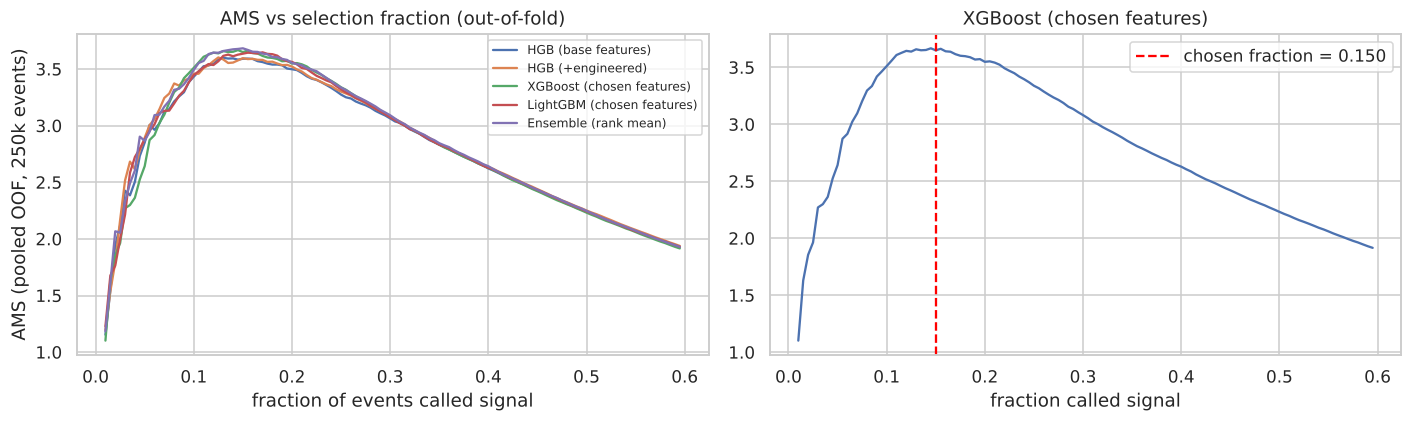

chosen fraction 0.150 -> pooled OOF AMS 3.649 (raw grid max 3.667); fractions within 0.05 AMS of the max: 0.115 - 0.165
per-fold AMS at the chosen fraction: [3.641 3.519 3.803 3.578 3.684] | mean 3.645 | std 0.097
Validation split, HGB: AMS at p>0.5 = 2.362 vs AMS at the best fraction = 3.555


In [26]:
FINAL_NAME = cvs.index[0]; print("Final model (best mean CV AMS):", FINAL_NAME)
curves = {}
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, s_ in oof.items():
    c_, _ = hu.ams_curve(y, s_, w); curves[k] = c_; ax[0].plot(hu.FRACS, c_, label=k)
ax[0].set_xlabel("fraction of events called signal"); ax[0].set_ylabel("AMS (pooled OOF, 250k events)"); ax[0].legend(fontsize=8); ax[0].set_title("AMS vs selection fraction (out-of-fold)")
bt = hu.best_threshold(y, oof[FINAL_NAME], w); FRAC = bt["frac"]
ax[1].plot(hu.FRACS, curves[FINAL_NAME]); ax[1].axvline(FRAC, color="red", ls="--", label=f"chosen fraction = {FRAC:.3f}")
ax[1].set_title(FINAL_NAME); ax[1].set_xlabel("fraction called signal"); ax[1].legend(); plt.tight_layout(); savefig("08_threshold_selection")
c = curves[FINAL_NAME]; plateau = hu.FRACS[c >= c.max() - 0.05]
print(f"chosen fraction {FRAC:.3f} -> pooled OOF AMS {bt['ams']:.3f} (raw grid max {bt['ams_max_raw']:.3f}); fractions within 0.05 AMS of the max: {plateau.min():.3f} - {plateau.max():.3f}")
pf = []
for f, (a, b) in enumerate(skf.split(X, y)):
    k_ = max(int(FRAC * len(b)), 1); o = np.argsort(-oof[FINAL_NAME][b])[:k_]; wb_ = w[b] * (N / len(b))
    pf.append(float(hu.ams(wb_[o][y[b][o] == 1].sum(), wb_[o][y[b][o] == 0].sum())))
print("per-fold AMS at the chosen fraction:", np.round(pf, 3), "| mean", round(np.mean(pf), 3), "| std", round(np.std(pf), 3))
e_row = pd.DataFrame(EXP).set_index("Experiment").loc["E-HGB"]
print(f"Validation split, HGB: AMS at p>0.5 = {e_row['AMS@0.5']:.3f} vs AMS at the best fraction = {e_row['AMS_best']:.3f}")
RESULTS.update({"final_model": FINAL_NAME, "chosen_fraction": FRAC, "oof_ams_at_fraction": bt["ams"], "oof_plateau": [float(plateau.min()), float(plateau.max())],
                "per_fold_ams_at_fraction": pf, "val_hgb_ams_at_0p5": float(e_row["AMS@0.5"]), "val_hgb_ams_best": float(e_row["AMS_best"])})

**Interpretation.** AMS rises sharply as the selection tightens from 60 % of events down to about 15 %, and then falls once too much signal is cut away. The pooled out-of-fold curve of the final model peaks at the top 15.0 % of events (OOF AMS 3.65) and is flat between 11.5 % and 16.5 % (within 0.05 AMS), so the exact choice is not critical; we selected the smoothed argmax on out-of-fold data only (never the test set). The five fold AMS values at this single fraction are 3.52–3.80 (mean 3.65, std 0.10). Compared with the default p > 0.5, the best cut raises validation AMS from 2.36 to 3.56 for HGB, the largest single improvement among all experiments except moving from linear to boosted models.

## 13. Interpretation: permutation importance and error analysis
Permutation importance is a clue about what the model uses, not a physical explanation (correlated features share importance). Computed on the validation split with a model trained on the training split.

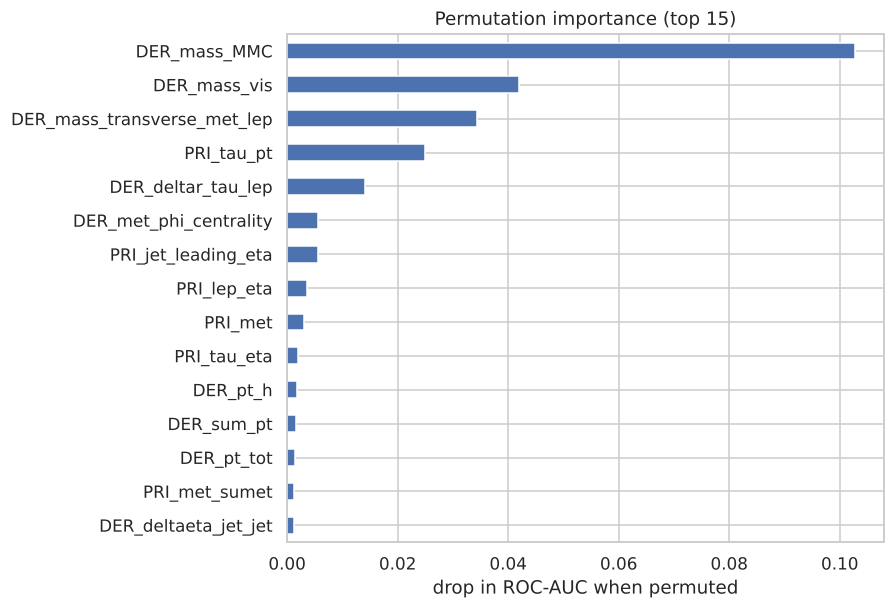

,AUC drop
DER_mass_MMC,0.1028
DER_mass_vis,0.0420
DER_mass_transverse_met_lep,0.0344
PRI_tau_pt,0.0250
DER_deltar_tau_lep,0.0142
DER_met_phi_centrality,0.0056
PRI_jet_leading_eta,0.0055
PRI_lep_eta,0.0035
PRI_met,0.0031
PRI_tau_eta,0.0020


In [27]:
final_val = make_gb("HGB"); final_val.fit(Xtr, ytr, **({} if SW is None else {"clf__sample_weight": SW}))
pi = permutation_importance(final_val, Xva, yva, scoring="roc_auc", n_repeats=3, random_state=SEED, n_jobs=1)
names_ = Xva.columns   # importance of the 30 raw input columns (engineered features are rebuilt from them inside the pipeline)
imp = pd.Series(pi.importances_mean, index=names_).sort_values(ascending=False)
plt.figure(figsize=(7, 6)); imp.head(15).iloc[::-1].plot.barh(color="#4c72b0"); plt.xlabel("drop in ROC-AUC when permuted"); plt.title("Permutation importance (top 15)"); savefig("09_permutation_importance")
RESULTS["perm_importance_top"] = imp.head(10).round(5).to_dict(); display(imp.head(10).round(4).to_frame("AUC drop"))

**Interpretation.** The model relies most on the mass estimates: `DER_mass_MMC` (AUC drop 0.103 when permuted), `DER_mass_vis` (0.042), `DER_mass_transverse_met_lep` (0.034) and `PRI_tau_pt` (0.025), followed by `DER_deltar_tau_lep`. This agrees with the EDA, where mass-type and tau-momentum variables separated the classes best. Because `DER_mass_MMC` and `DER_mass_vis` are strongly correlated (ρ = 0.86) their importance is partly shared, and permutation importance is a clue about what the model uses, not proof of a physical mechanism.

threshold: top 0.165 of events -> validation AMS 3.555


outcome,FN,FP,TN,TP
events,9789.0,906.0,31961.0,7344.0
weight,438.8,5084.3,405302.1,255.8


,events,bkg weight selected (FP),signal weight found (TP),signal weight missed (FN),FP events,signal recall (weighted),s/sqrt(b)
jet,,,,,,,
0,19960.0,2756.34,130.57,233.43,225.0,0.36,2.49
1,15505.0,1430.70,62.98,144.38,225.0,0.30,1.67
2,14535.0,897.25,62.30,60.97,456.0,0.51,2.08


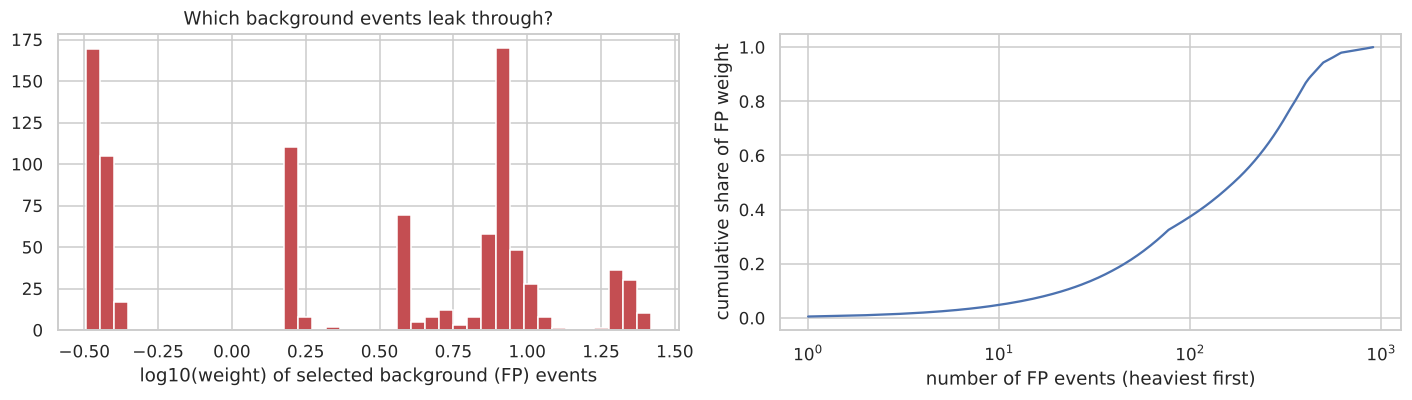

heaviest 1% of FP events carry 0.044 of the total FP weight


,DER_mass_MMC,DER_mass_transverse_met_lep,DER_mass_vis,PRI_tau_pt
outcome,,,,
FN,113.3,35.9,76.1,33.2
FP,122.2,17.3,80.3,48.1
TN,101.0,62.0,69.2,28.3
TP,127.9,15.1,83.4,51.4


share of events with undefined MMC among FN / TP / FP: {'FN': 0.06, 'TP': 0.002, 'FP': 0.001}


In [28]:
s_v = final_val.predict_proba(Xva)[:, 1]; thr_v = best_of(s_v)
pred = (s_v >= thr_v["thr"]).astype(int)
ea = pd.DataFrame({"y": yva, "pred": pred, "w": wva, "jet": np.minimum(Xva.PRI_jet_num.astype(int).to_numpy(), 2), "mmc_undef": (Xva.DER_mass_MMC == -999).to_numpy()})
ea["outcome"] = np.select([(ea.y==1)&(ea.pred==1), (ea.y==0)&(ea.pred==1), (ea.y==1)&(ea.pred==0)], ["TP","FP","FN"], "TN")
print(f"threshold: top {thr_v['frac']:.3f} of events -> validation AMS {thr_v['ams']:.3f}")
display(ea.groupby("outcome").agg(events=("w","size"), weight=("w","sum")).round(1).T)
tab = ea.groupby("jet").apply(lambda d: pd.Series({"events": len(d), "bkg weight selected (FP)": d.w[d.outcome=="FP"].sum(), "signal weight found (TP)": d.w[d.outcome=="TP"].sum(), "signal weight missed (FN)": d.w[d.outcome=="FN"].sum(), "FP events": (d.outcome=="FP").sum()}))
tab["signal recall (weighted)"] = tab["signal weight found (TP)"] / (tab["signal weight found (TP)"] + tab["signal weight missed (FN)"])
tab["s/sqrt(b)"] = tab["signal weight found (TP)"] / np.sqrt(tab["bkg weight selected (FP)"] + 1e-9)
display(tab.round(2)); RESULTS["error_by_jet"] = tab.round(3).reset_index().to_dict("records")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
fpw = ea.w[ea.outcome == "FP"]; ax[0].hist(np.log10(fpw), bins=40, color="#c44e52"); ax[0].set_xlabel("log10(weight) of selected background (FP) events"); ax[0].set_title("Which background events leak through?")
fps = np.sort(fpw.to_numpy())[::-1]; ax[1].plot(np.arange(1, len(fps)+1), np.cumsum(fps)/fps.sum()); ax[1].set_xlabel("number of FP events (heaviest first)"); ax[1].set_ylabel("cumulative share of FP weight"); ax[1].set_xscale("log")
plt.tight_layout(); savefig("10_false_positive_weights")
top1 = float(fps[:max(1, len(fps)//100)].sum()/fps.sum()); print("heaviest 1% of FP events carry", round(top1, 3), "of the total FP weight"); RESULTS["fp_top1pct_weight_share"] = top1
cmpf = ["DER_mass_MMC","DER_mass_transverse_met_lep","DER_mass_vis","PRI_tau_pt"]
tmp = hu.to_nan(Xva).assign(outcome=ea.outcome.to_numpy())
display(tmp.groupby("outcome")[cmpf].median().round(1)); RESULTS["fp_fn_medians"] = tmp.groupby("outcome")[cmpf].median().round(2).to_dict()
RESULTS["mmc_undef_share"] = {"FN": float(ea[ea.outcome=="FN"].mmc_undef.mean()), "TP": float(ea[ea.outcome=="TP"].mmc_undef.mean()), "FP": float(ea[ea.outcome=="FP"].mmc_undef.mean())}
print("share of events with undefined MMC among FN / TP / FP:", {k: round(v, 3) for k, v in RESULTS["mmc_undef_share"].items()})

**Interpretation.** At the chosen cut the model selects about 15 % of events. Weighted signal recall is only 36 % for 0-jet, 30 % for 1-jet and 51 % for ≥ 2-jet events; the per-group s/√b is 2.49, 1.67 and 2.08, so the 1-jet group contributes least and the 0-jet group, with the most background weight leaking through (2756 vs 1431 and 897), is the largest source of FP weight. False positives look like true positives (median `DER_mass_MMC` 122 vs 128 GeV, `PRI_tau_pt` 48 vs 51, transverse mass 17 vs 15), i.e. they are genuinely signal-like background. Missed signals (FN) look more background-like (transverse mass 36, tau pt 33). Events with undefined `DER_mass_MMC` are 6 % of FN but only 0.2 % of TP: the model essentially treats them as background, which is mostly correct (7.4 % of them are signal). False-positive weight is not concentrated in a few heavy events: the heaviest 1 % carry only 4.4 % of the FP weight, so the AMS penalty comes from many moderate-weight background events.

## 14. Final model, test predictions and Kaggle submission file
The final model is retrained on **all 250 000 training events** with the chosen preprocessing and weighting. The test file is used only to produce predictions. The top `FRAC` of test events (by score) are labelled `s`; `RankOrder` is a permutation of 1…N where a higher rank means more signal-like.

In [29]:
t0 = time.time()
swf = {"none": None, "raw Weight": w, "class-balanced": hu.class_balanced_weights(y, w)}[best_w]
comp = ENS_MEMBERS if FINAL_NAME.startswith("Ensemble") else [FINAL_NAME]
test_scores = []
for k in comp:
    kind, fn = CV_SPECS[k]; m = build(kind, fn); m.fit(X, y, **({} if swf is None else {"clf__sample_weight": swf}))
    test_scores.append(rk(m.predict_proba(Xtest)[:, 1])); print(k, "fitted", f"({time.time()-t0:.0f}s)")
score_test = np.mean(test_scores, axis=0)
order = np.argsort(np.argsort(score_test, kind="stable"), kind="stable") + 1      # 1 = most background-like ... N = most signal-like
NT = len(score_test); cut = int(round(NT * (1 - FRAC)))
sub = pd.DataFrame({"EventId": test_ids, "RankOrder": order, "Class": np.where(order > cut, "s", "b")})
sub_path = f"{SUB}/submission.csv" if not QUICK else f"{SUB}/submission_QUICK_TEST_ONLY.csv"
sub.to_csv(sub_path, index=False)
assert sub.EventId.tolist() == list(test_ids), "EventId order changed"
assert sorted(sub.RankOrder) == list(range(1, NT + 1)), "RankOrder is not a permutation"
assert set(sub.Class) <= {"s", "b"}
print(f"written: {sub_path} | rows {NT} | predicted signal share {(sub.Class=='s').mean():.3f} (target {FRAC:.3f}) | all format checks passed")
rs = pd.read_csv(f"{DATA}/random_submission.csv", nrows=3); print("sample-file columns:", list(rs.columns), "| ours:", list(sub.columns))
if not QUICK: print("test EventIds identical to test.csv:", bool((pd.read_csv(f"{DATA}/test.csv", usecols=["EventId"]).EventId.to_numpy() == sub.EventId.to_numpy()).all()))
RESULTS["submission"] = {"rows": int(NT), "signal_fraction": float((sub.Class == "s").mean()), "members": comp}

XGBoost (chosen features) fitted (15s)


written: ../submission/submission.csv | rows 550000 | predicted signal share 0.150 (target 0.150) | all format checks passed
sample-file columns: ['EventId', 'RankOrder', 'Class'] | ours: ['EventId', 'RankOrder', 'Class']


test EventIds identical to test.csv: True


> **Note:** the official test labels and weights are not public, so the leaderboard AMS cannot be computed offline. The honest estimate of final performance is the cross-validated out-of-fold AMS above. The Kaggle public/private leaderboard split also differs from our folds, so the leaderboard number will differ somewhat.

## 15. Conclusions and limitations

**Final recommendation.** XGBoost on the 30 original features (`-999` → NaN, no scaling), class-balanced sample weights, 300 trees, learning rate 0.08, depth 6, followed by labelling the top 15 % of events (by score) as signal. Estimated AMS ≈ 3.65 (pooled out-of-fold, per-fold range 3.5–3.8). The final model was refit on all 250,000 training events and used to create `submission.csv`.

**What the evidence showed.** (1) Accuracy and AMS disagree: the best-accuracy configuration is not the best-AMS one. (2) Event weights must be used for evaluation and handled carefully in training: class-balanced weights beat both unweighted and raw weights. (3) The AMS threshold matters a lot: p > 0.5 gives 2.36 where the best cut gives 3.56. (4) Boosted trees beat linear models by a wide margin and beat bagging; the three boosting libraries are statistically tied. (5) The treatment of `-999` barely matters for boosted trees. (6) Engineered features, feature subsets, per-jet models and an ensemble did not give gains larger than the noise. An experiment that did not work as expected: the per-jet-group models (AMS 3.36 vs 3.56) and raw-weight training (AMS 3.15).

**Limitations.** The test labels and weights are not public, so the leaderboard AMS cannot be reproduced here; the out-of-fold estimate is the best available and the leaderboard value will differ because of the different split and sample size. AMS is noisy (fold std 0.1–0.3). The fraction was selected on the same out-of-fold predictions used for estimating performance, so the 3.65 is slightly optimistic. Hyper-parameters were set once, not tuned. The weight scaling by `N_train/N_val` assumes the competition's weight normalisation. Only one random seed was used for the model fits. Permutation importance does not prove a physical explanation.

**What I would investigate next.** Tune the XGBoost/LightGBM hyper-parameters inside cross-validation; repeat CV with several seeds to put error bars on model differences; try a neural network on the same features; test monotonic or smoothed fraction selection; and investigate the 1-jet group, which has the lowest s/√b.

In [30]:
RESULTS["n_train"] = int(N); RESULTS["quick"] = QUICK
json.dump(RESULTS, open(f"{RES}/results{'_quick' if QUICK else ''}.json", "w"), indent=1, default=float)
print("saved results; keys:", list(RESULTS))

saved results; keys: ['class_table', 'missing_pct', 'single_feature_auc_top', 'high_corr_pairs', 'baselines', 'best_weight_scheme', 'fit_seconds', 'auc_vs_ams_rank_corr', 'use_fe', 'fe_auc_gain', 'fe_ams_gain', 'cv_summary', 'final_model', 'chosen_fraction', 'oof_ams_at_fraction', 'oof_plateau', 'per_fold_ams_at_fraction', 'val_hgb_ams_at_0p5', 'val_hgb_ams_best', 'perm_importance_top', 'error_by_jet', 'fp_top1pct_weight_share', 'fp_fn_medians', 'mmc_undef_share', 'submission', 'n_train', 'quick']


### References
* Kaggle competition page, Data and Evaluation sections: https://www.kaggle.com/competitions/higgs-boson/overview
* CERN Open Data record 328 (ATLAS Higgs Challenge dataset): https://opendata.cern.ch/record/328
* Adam-Bourdarios et al., *The Higgs boson machine learning challenge*, JMLR W&CP 42 (2015): description of the data and the AMS.
* scikit-learn, XGBoost and LightGBM documentation for the APIs used.

All code in this notebook was written for this project; no public notebook was copied.